In [2]:
import kagglehub
import shutil
from pathlib import Path
 


PROJECT_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("بدء تحميل بيانات Olist...")


dataset_path = kagglehub.dataset_download(
    "olistbr/brazilian-ecommerce"
)

source_dir = Path(dataset_path)
print(f"تم تنزيل الداتا في مسار الكاش: {source_dir}")


csv_files = list(source_dir.glob("*.csv"))

for file in csv_files:
    destination = RAW_DATA_DIR / file.name
    shutil.copy2(file, destination)
    print(f"تم نسخ الملف: {file.name}")

print("تم الانتهاء من جمع وتنزيل جميع الملفات بنجاح!")

بدء تحميل بيانات Olist...
تم تنزيل الداتا في مسار الكاش: C:\Users\dell\.cache\kagglehub\datasets\olistbr\brazilian-ecommerce\versions\2
تم نسخ الملف: olist_customers_dataset.csv
تم نسخ الملف: olist_geolocation_dataset.csv
تم نسخ الملف: olist_orders_dataset.csv
تم نسخ الملف: olist_order_items_dataset.csv
تم نسخ الملف: olist_order_payments_dataset.csv
تم نسخ الملف: olist_order_reviews_dataset.csv
تم نسخ الملف: olist_products_dataset.csv
تم نسخ الملف: olist_sellers_dataset.csv
تم نسخ الملف: product_category_name_translation.csv
تم الانتهاء من جمع وتنزيل جميع الملفات بنجاح!


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd

df_sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")

# عرض شكله
print("Sellers Shape:", df_sellers.shape)
display(df_sellers.head(3))

Sellers Shape: (3095, 4)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


In [4]:
# seller_id(تاكد من عدم تكرار id)
print("Total Rows:", len(df_sellers))
print("Unique Seller IDs:", df_sellers['seller_id'].nunique())


print("\nTop 5 Seller States:")
print(df_sellers['seller_state'].value_counts().head(5))


print("\nTop 5 Seller Cities:")
print(df_sellers['seller_city'].value_counts().head(5))

Total Rows: 3095
Unique Seller IDs: 3095

Top 5 Seller States:
seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
Name: count, dtype: int64

Top 5 Seller Cities:
seller_city
sao paulo         694
curitiba          127
rio de janeiro     96
belo horizonte     68
ribeirao preto     52
Name: count, dtype: int64


In [5]:
# ==============================
# 6. Geographic Data Analysis
# ==============================

df_geolocation = pd.read_csv(
    "../data/raw/olist_geolocation_dataset.csv"
)

print("Geolocation Shape:", df_geolocation.shape)

print("\nGeolocation Missing Values:")
print(df_geolocation.isnull().sum())

# Aggregate geolocation records by ZIP prefix
df_geo_summary = (
    df_geolocation.groupby("geolocation_zip_code_prefix")
    .agg(
        latitude=("geolocation_lat", "mean"),
        longitude=("geolocation_lng", "mean")
    )
    .reset_index()
)

df_sellers_geo = pd.merge(
    df_sellers,
    df_geo_summary,
    left_on="seller_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left",
    validate="many_to_one"
)

print("\nSellers with Geographic Coordinates:",
      df_sellers_geo["latitude"].notna().sum())
print("Sellers without Geographic Coordinates:",
      df_sellers_geo["latitude"].isna().sum())

Geolocation Shape: (1000163, 5)

Geolocation Missing Values:
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

Sellers with Geographic Coordinates: 3088
Sellers without Geographic Coordinates: 7


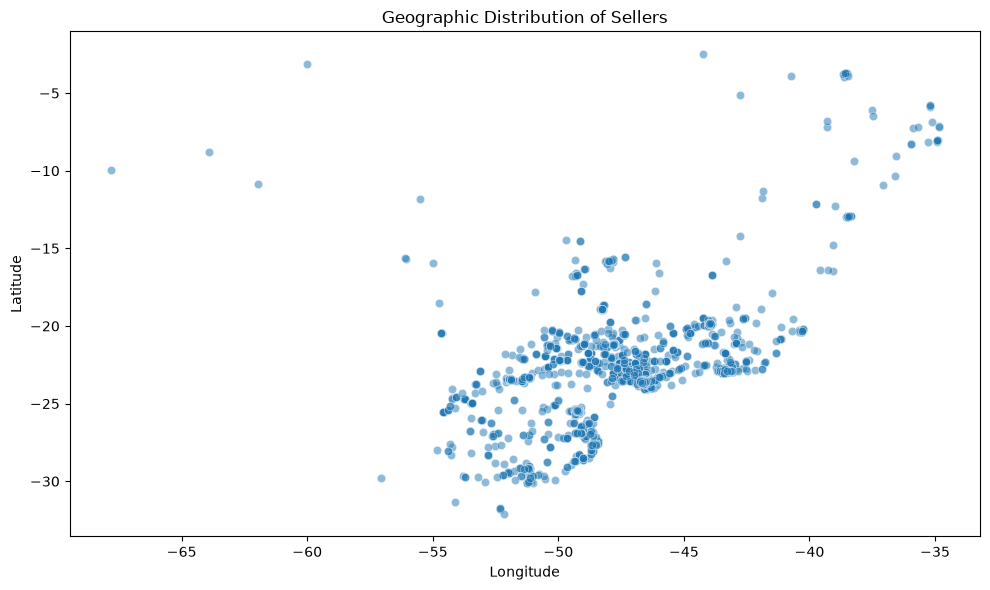

In [7]:
# ==============================
# 7. Seller Geographic Visualization
# ==============================

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_sellers_geo,
    x="longitude",
    y="latitude",
    alpha=0.5
)
plt.title("Geographic Distribution of Sellers")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

In [8]:
# ==============================
# 8. Seller and Orders Relationship
# ==============================

df_order_items = pd.read_csv(
    "../data/raw/olist_order_items_dataset.csv"
)

seller_orders = (
    df_order_items.groupby("seller_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_items=("order_id", "count"),
        total_revenue=("price", "sum")
    )
    .reset_index()
)

print("\nSeller Orders Statistics:")
display(seller_orders[["total_orders", "total_items", "total_revenue"]].describe())


Seller Orders Statistics:


,total_orders,total_items,total_revenue
count,3095.000000,3095.000000,3095.000000
mean,32.313409,36.397415,4391.484233
std,105.139763,119.193461,13921.997192
min,1.000000,1.000000,3.500000
25%,2.000000,2.000000,208.850000
50%,6.000000,8.000000,821.480000
75%,21.500000,24.000000,3280.830000
max,1854.000000,2033.000000,229472.630000


In [9]:
# ==============================
# 9. Merge Sellers with Orders
# ==============================

df_sellers_orders = pd.merge(
    df_sellers,
    seller_orders,
    on="seller_id",
    how="left",
    validate="one_to_one"
)

print("\nTop 10 Sellers by Number of Orders:")
display(
    df_sellers_orders
    .sort_values("total_orders", ascending=False)
    [["seller_id", "seller_city", "seller_state",
      "total_orders", "total_items", "total_revenue"]]
    .head(10)
)


Top 10 Sellers by Number of Orders:


,seller_id,seller_city,seller_state,total_orders,total_items,total_revenue
797,6560211a19b47992c3666cc44a7e94c0,sao paulo,SP,1854,2033,123304.83
2463,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92
1413,cc419e0650a3c5ba77189a1882b7556a,santo andre,SP,1706,1775,104288.42
474,1f50f920176fa81dab994f9023523100,sao jose do rio preto,SP,1404,1931,106939.21
1873,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57
390,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1287,1499,135171.70
2207,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53
987,ea8482cd71df3c1969d7b9473ff13abc,sao paulo,SP,1146,1203,37177.52
2617,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63
2345,3d871de0142ce09b7081e2b9d1733cb1,campo limpo paulista,SP,1080,1147,94914.20


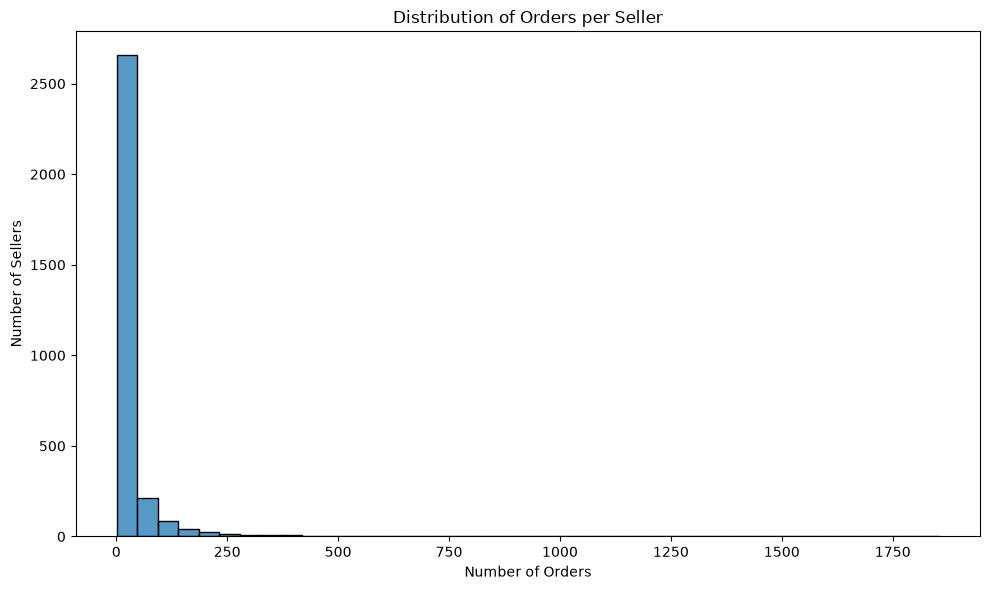

In [10]:
# ==============================
# 10. Seller Orders Visualization
# ==============================

plt.figure(figsize=(10, 6))
sns.histplot(
    data=seller_orders,
    x="total_orders",
    bins=40
)
plt.title("Distribution of Orders per Seller")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Sellers")
plt.tight_layout()
plt.show()

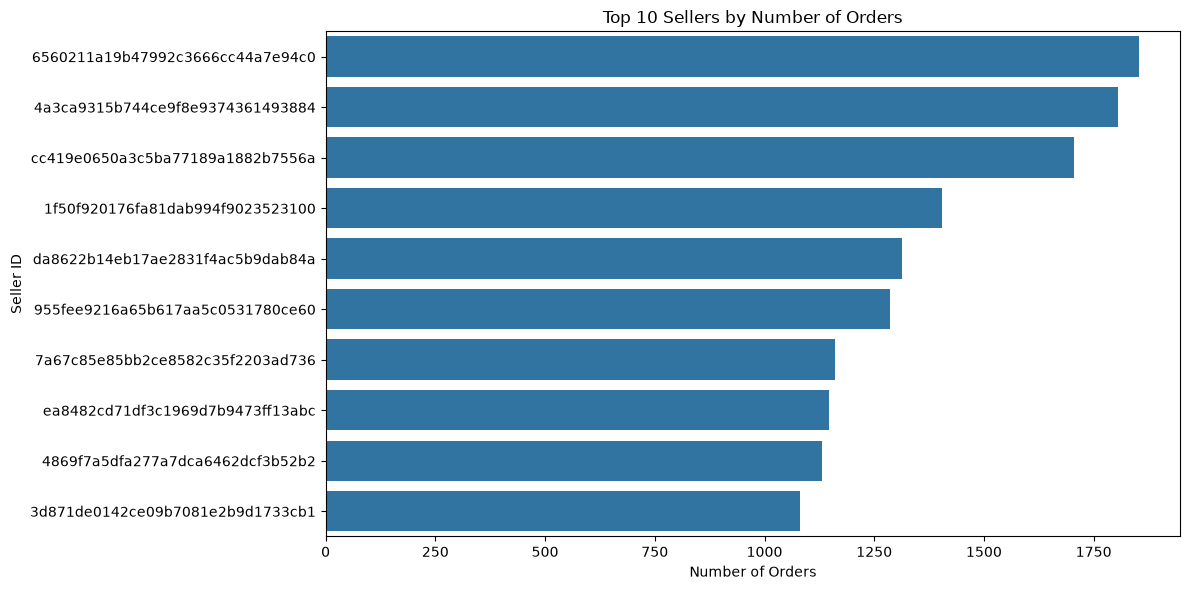

In [11]:
# ==============================
# 11. Top Sellers Visualization
# ==============================

top_sellers = seller_orders.nlargest(10, "total_orders")

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_sellers,
    x="total_orders",
    y="seller_id"
)
plt.title("Top 10 Sellers by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Seller ID")
plt.tight_layout()
plt.show()

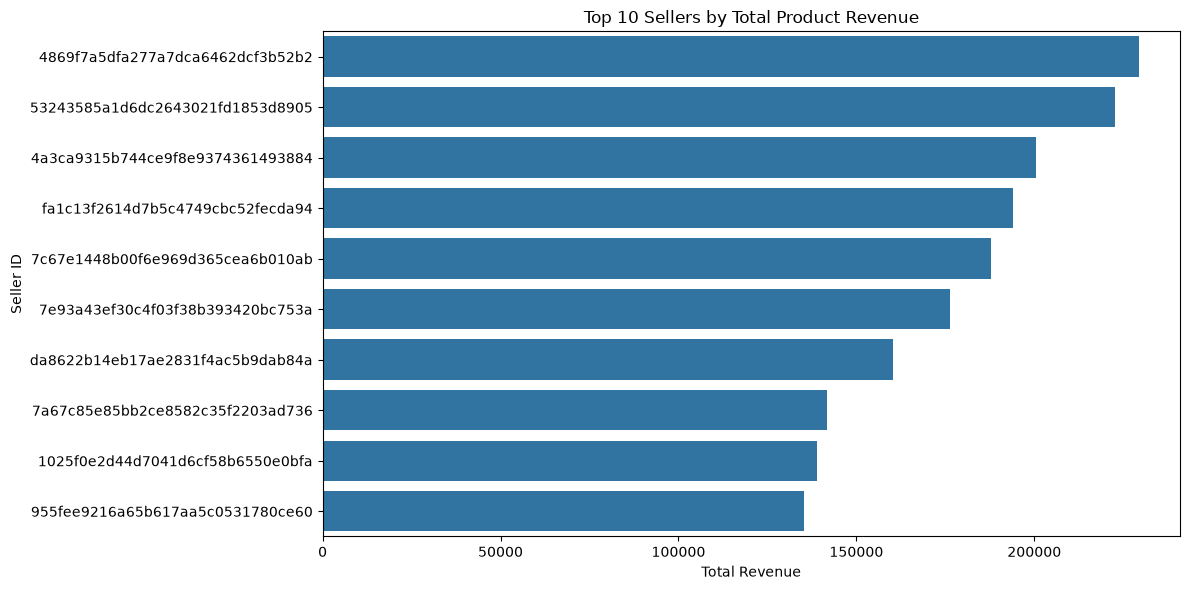

In [12]:
# ==============================
# 12. Seller Revenue Analysis (BEST SELLER)
# ==============================

top_revenue_sellers = seller_orders.nlargest(10, "total_revenue")

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_revenue_sellers,
    x="total_revenue",
    y="seller_id"
)
plt.title("Top 10 Sellers by Total Product Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Seller ID")
plt.tight_layout()
plt.show()